# Embudo de conversión de leads · después del ETL
**Autor:** Juan Camilo Castro López

Con los datos ya limpios por `src/etl.py`, respondo: **¿qué fuentes, canales y servicios convierten mejor de lead → cita agendada → cliente, y cuánto ingreso generan?**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False})
AZUL, GRIS, NARANJA = "#2a6f97", "#9aa5b1", "#e07a2f"

raw = pd.read_csv("data/raw/leads_export.csv", dtype=str)
df = pd.read_csv("data/processed/leads_limpios.csv", parse_dates=["fecha_creacion"], dtype={"telefono": str})
print(f"Crudo: {len(raw)} filas  ->  Limpio: {len(df)} filas")

Crudo: 1950 filas  ->  Limpio: 1799 filas


## 1. Antes vs. después de la limpieza

In [2]:
print("Ejemplos crudos de ciudad:", raw.ciudad.dropna().unique()[:10])
print("Ciudades limpias:", sorted(df.ciudad.unique()))
print()
print("Ejemplos crudos de teléfono:", raw.telefono.head(5).tolist())
print("Teléfonos limpios:", df.telefono.head(5).tolist())
print()
orig = raw[~raw.id_origen.str.contains("-D")]
print("Formatos de fecha crudos:", orig.groupby("fuente").fecha_creacion.first().to_dict())

Ejemplos crudos de ciudad: <StringArray>
[       'cali',        'CALI',      'bogota',      'Bogotá',   'Medellin ',
 'bucaramanga', 'BOGOTA D.C.',    'B/quilla',    ' Bogotá ',    'Medellín']
Length: 10, dtype: str
Ciudades limpias: ['Barranquilla', 'Bogotá', 'Bucaramanga', 'Cali', 'Medellín', 'Sin dato']

Ejemplos crudos de teléfono: ['(323) 1828598', '(323) 9024845', '3229111896', '3286541170', '303-115-5138']
Teléfonos limpios: ['+573249622497', '+573131348585', '+573222632398', '+573004559004', '+573057592910']

Formatos de fecha crudos: {'calendly': '27/03/2025 19:27', 'google_sheets': '21-Apr-2025', 'wordpress_form': '2025-02-19 13:40:00'}


## 2. Embudo general

Leads             1799
Agendaron cita     916
Clientes           367

Lead -> Cita: 50.9% | Cita -> Cliente: 40.1% | Lead -> Cliente: 20.4%


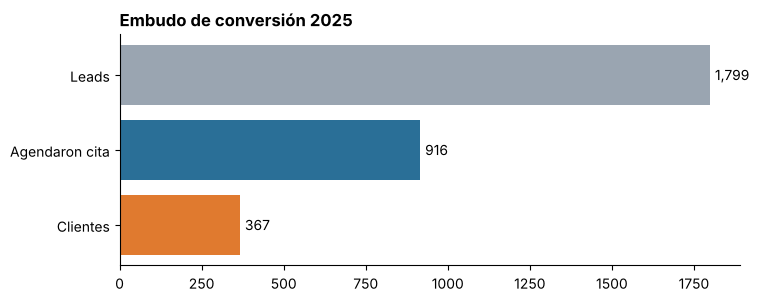

In [3]:
embudo = pd.Series({"Leads": len(df), "Agendaron cita": df.agendo_cita.sum(), "Clientes": df.es_cliente.sum()})
print(embudo.to_string())
print(f"\nLead -> Cita: {embudo.iloc[1]/embudo.iloc[0]:.1%} | Cita -> Cliente: {embudo.iloc[2]/embudo.iloc[1]:.1%} | Lead -> Cliente: {embudo.iloc[2]/embudo.iloc[0]:.1%}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(embudo.index[::-1], embudo.values[::-1], color=[NARANJA, AZUL, GRIS])
for i, v in enumerate(embudo.values[::-1]): ax.text(v + 15, i, f"{v:,}", va="center")
ax.set_title("Embudo de conversión 2025", loc="left", fontweight="bold")

## 3. Conversión por fuente y por canal

In [4]:
def resumen(col):
    g = df.groupby(col).agg(leads=("lead_id", "size"), citas=("agendo_cita", "sum"),
                            clientes=("es_cliente", "sum"), ingresos=("valor_venta", "sum"))
    g["lead_a_cliente_%"] = 100 * g.clientes / g.leads
    g["cita_a_cliente_%"] = 100 * g.clientes / g.citas
    g["ingreso_por_lead"] = g.ingresos / g.leads
    return g.sort_values("lead_a_cliente_%", ascending=False)

pd.set_option("display.float_format", "{:,.1f}".format)
print(resumen("fuente").to_string()); print()
canal = resumen("canal"); print(canal.to_string())

                leads  citas  clientes      ingresos  lead_a_cliente_%  cita_a_cliente_%  ingreso_por_lead
fuente                                                                                                    
calendly          476    476       219 106,570,000.0              46.0              46.0         223,886.6
wordpress_form    814    291        94  43,080,000.0              11.5              32.3          52,923.8
google_sheets     509    149        54  25,280,000.0              10.6              36.2          49,666.0

             leads  citas  clientes     ingresos  lead_a_cliente_%  cita_a_cliente_%  ingreso_por_lead
canal                                                                                                 
Referido       206    104        51 24,320,000.0              24.8              49.0         118,058.3
Google Ads     442    232        91 46,710,000.0              20.6              39.2         105,678.7
Orgánico       384    193        77 32,380,000.0    

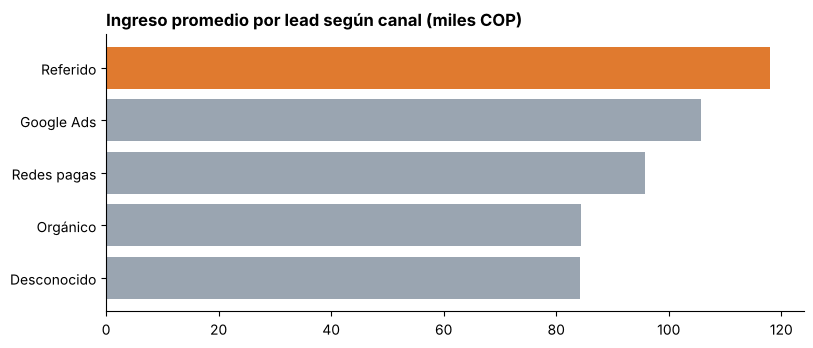

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
c = canal.sort_values("ingreso_por_lead")
ax.barh(c.index, c.ingreso_por_lead / 1000, color=[NARANJA if i == c.index[-1] else GRIS for i in c.index])
ax.set_title("Ingreso promedio por lead según canal (miles COP)", loc="left", fontweight="bold")

## 4. Servicios y tendencia mensual

                     leads  clientes  cita_a_cliente_%     ingresos
servicio                                                           
Asesoría migratoria    194        54              52.9 24,530,000.0
Trámite de visa        538       116              42.6 58,040,000.0
Apostilla              363        71              37.2 32,450,000.0
Pasaporte              430        83              38.8 40,340,000.0
Traducción oficial     274        43              31.4 19,570,000.0


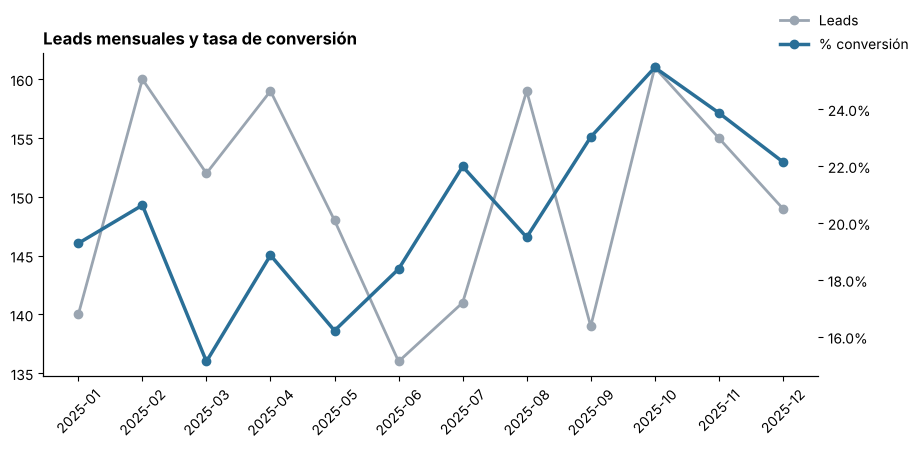

In [6]:
serv = resumen("servicio"); print(serv[["leads", "clientes", "cita_a_cliente_%", "ingresos"]].to_string())

mes = df.groupby("mes").agg(leads=("lead_id", "size"), clientes=("es_cliente", "sum"))
fig, ax = plt.subplots()
ax.plot(mes.index, mes.leads, color=GRIS, lw=2, marker="o", label="Leads")
ax2 = ax.twinx(); ax2.plot(mes.index, 100 * mes.clientes / mes.leads, color=AZUL, lw=2.5, marker="o", label="% conversión")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.spines["top"].set_visible(False)
ax.tick_params(axis="x", rotation=45); ax.set_title("Leads mensuales y tasa de conversión", loc="left", fontweight="bold")
fig.legend(loc="upper right", frameon=False)

## 5. Hallazgos
- La limpieza eliminó **151 duplicados** (≈7,7% del archivo) que inflaban los leads y distorsionaban la conversión.
- **Calendly** convierte **46%** de sus leads en clientes vs. **11,5%** de los formularios de WordPress, porque el lead ya llega con cita: conviene enlazar el agendamiento directamente desde los formularios de WordPress.
- **Referido** genera el mayor ingreso por lead (~118 mil COP vs ~96 mil de Redes pagas) → fortalecer el programa de referidos antes de aumentar pauta.
- *Asesoría migratoria* tiene la mayor tasa de cierre después de la cita (**52,9%**) → buen candidato para campañas específicas.

El archivo `leads_limpios.csv` queda listo para alimentar un tablero en Power BI / Looker Studio.